In [1]:
import duckdb, pandas as pd, matplotlib.pyplot as plt
con = duckdb.connect()
con.execute("SET memory_limit='300MB'")
con.execute("SET temp_directory='/tmp/duckdb_tmp'")
con.execute("SET threads=1")

In [2]:
df_rod = con.execute("""
    SELECT "Complaint Type" AS ctype,
           coalesce("Location Type", 'Not recorded') AS location_type,
           count(*) AS n
    FROM read_csv('311_only_2024.csv', header=true, all_varchar=true)
    WHERE lower("Complaint Type") LIKE '%rodent%'
      AND year(try_strptime("Created Date", '%m/%d/%Y %I:%M:%S %p')) = 2024
    GROUP BY 1, 2
""").df()

print(df_rod.groupby('ctype')['n'].sum())   # confirm which complaint types matched

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

ctype
Rodent    39728
Name: n, dtype: int64


In [3]:
rodent = (df_rod.groupby('location_type')['n'].sum()
                .sort_values(ascending=False)
                .rename('complaints')
                .to_frame())
rodent['percent'] = (rodent['complaints'] / rodent['complaints'].sum() * 100).round(1)

print('total rodent complaints:', rodent['complaints'].sum())
rodent

total rodent complaints: 39728


,complaints,percent
location_type,,
3+ Family Apt. Building,20197,50.8
1-2 Family Dwelling,7350,18.5
Other (Explain Below),5273,13.3
3+ Family Mixed Use Building,2052,5.2
Commercial Building,1708,4.3
Vacant Lot,708,1.8
1-2 Family Mixed Use Building,543,1.4
Construction Site,514,1.3
Parking Lot/Garage,435,1.1


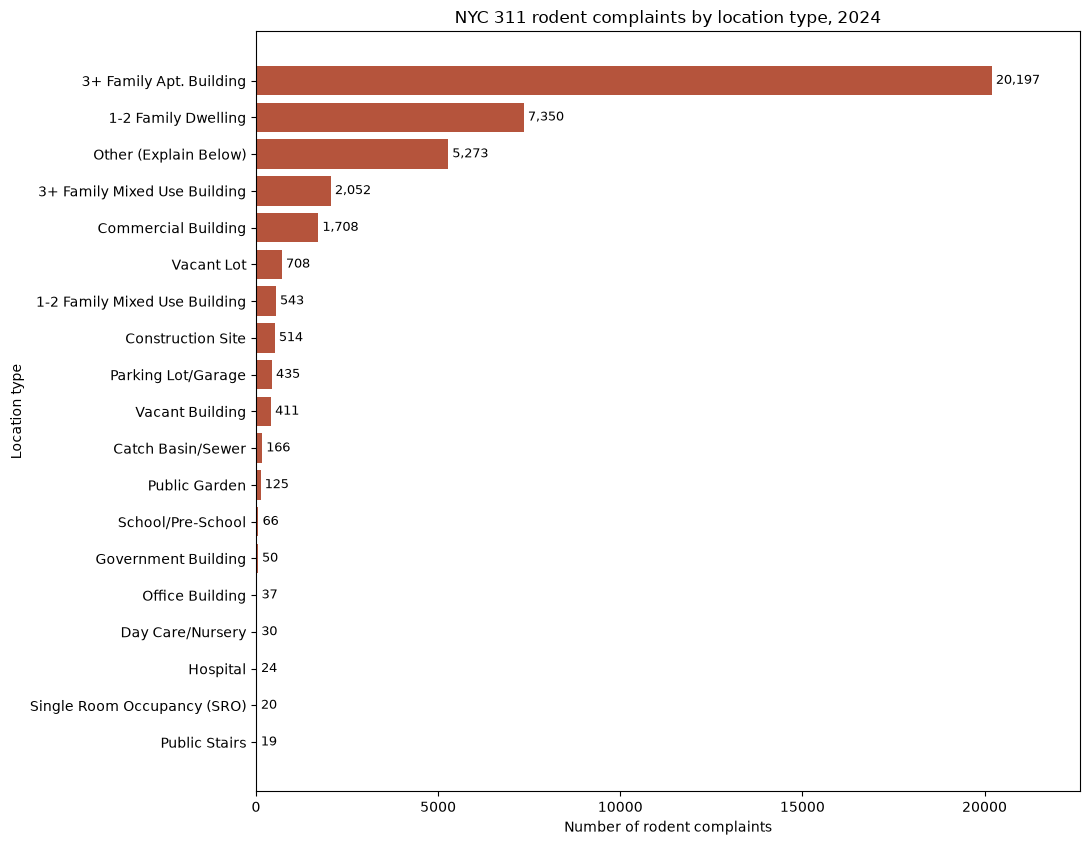

In [4]:
fig, ax = plt.subplots(figsize=(11, max(4, 0.45 * len(rodent))))
bars = ax.barh(rodent.index[::-1], rodent['complaints'][::-1], color='#b5543c')
ax.bar_label(bars, labels=[f'{v:,}' for v in rodent['complaints'][::-1]], padding=3, fontsize=9)
ax.set_xlabel('Number of rodent complaints')
ax.set_ylabel('Location type')
ax.set_title('NYC 311 rodent complaints by location type, 2024')
ax.set_xlim(0, rodent['complaints'].max() * 1.12)
plt.tight_layout()
plt.savefig('rodent_by_location.png', dpi=200)
plt.show()